# Evaluation Figures

This notebook visualizes exact vs semantic agreement metrics from `results/evaluation_report.json`.

Figures are saved to `results/figures/`. The style is configured for Times New Roman and larger font sizes.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(
    context="paper",
    style="whitegrid",
    font="Times New Roman",
    font_scale=1.6,
)
palette = sns.color_palette("Set2")

REPORT_PATH = Path("results/evaluation_report.json")
FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

with REPORT_PATH.open("r", encoding="utf-8") as f:
    report = json.load(f)

exact = report["exact"] if "exact" in report else report
semantic = report.get("semantic")
if semantic is None:
    raise ValueError("This notebook expects a semantic report. Run: python src/evaluate.py --semantic --semantic-threshold 0.85")

VIEWS = ["fields", "values", "field_value_pairs"]
VIEW_LABELS = {
    "fields": "Fields",
    "values": "Values",
    "field_value_pairs": "Field + Value",
}
MODEL_LABELS = {
    "deepseek/deepseek-v4-flash": "DeepSeek",
    "qwen/qwen3.5-flash-02-23": "Qwen 3.5",
    "qwen/qwen3.6-flash": "Qwen 3.6",
}

plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 20,
    "xtick.labelsize": 17,
    "ytick.labelsize": 17,
    "legend.fontsize": 16,
    "figure.titlesize": 24,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COLORS = {
    "exact": "#4C78A8",
    "semantic": "#F58518",
    "gain": "#54A24B",
}

print("Loaded report:", REPORT_PATH)
print("Common docs:", exact["common_doc_count"])
print("Semantic backend:", semantic["semantic"]["backend"])
print("Semantic threshold:", semantic["semantic"]["threshold"])

Loaded report: results/evaluation_report.json
Common docs: 196
Semantic backend: sentence-transformers/all-MiniLM-L6-v2
Semantic threshold: 0.85


## Helper Functions

In [2]:
def save_figure(fig, name):
    png_path = FIG_DIR / f"{name}.png"
    pdf_path = FIG_DIR / f"{name}.pdf"
    fig.savefig(png_path, dpi=300, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved {png_path}")
    print(f"Saved {pdf_path}")


def bar_label(ax, bars, fmt="{:.2f}"):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            fmt.format(height),
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=13,
        )


def grouped_exact_semantic_bars(ax, exact_values, semantic_values, title, ylabel="Score"):
    x = np.arange(len(VIEWS))
    width = 0.36
    b1 = ax.bar(x - width / 2, exact_values, width, label="Exact", color=COLORS["exact"])
    b2 = ax.bar(x + width / 2, semantic_values, width, label="Semantic", color=COLORS["semantic"])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
    ax.set_ylim(0, max(max(exact_values), max(semantic_values), 0.01) * 1.22)
    ax.grid(axis="y", alpha=0.25)
    bar_label(ax, b1)
    bar_label(ax, b2)
    return ax


def pairwise_matrix(report_obj, view, metric_key):
    models = report_obj["models"]
    matrix = np.eye(len(models))
    for pair in report_obj["pairwise"]:
        i = models.index(pair["model_a"])
        j = models.index(pair["model_b"])
        value = pair["averages"][view][metric_key]
        matrix[i, j] = value
        matrix[j, i] = value
    return models, matrix


def draw_heatmap(ax, matrix, labels, title, vmin=0, vmax=1):
    im = ax.imshow(matrix, cmap="Blues", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticklabels(labels)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=15)
    return im

## Figure 1: Exact vs Semantic Pairwise Agreement

Saved results/figures/fig1_exact_vs_semantic_pairwise.png
Saved results/figures/fig1_exact_vs_semantic_pairwise.pdf


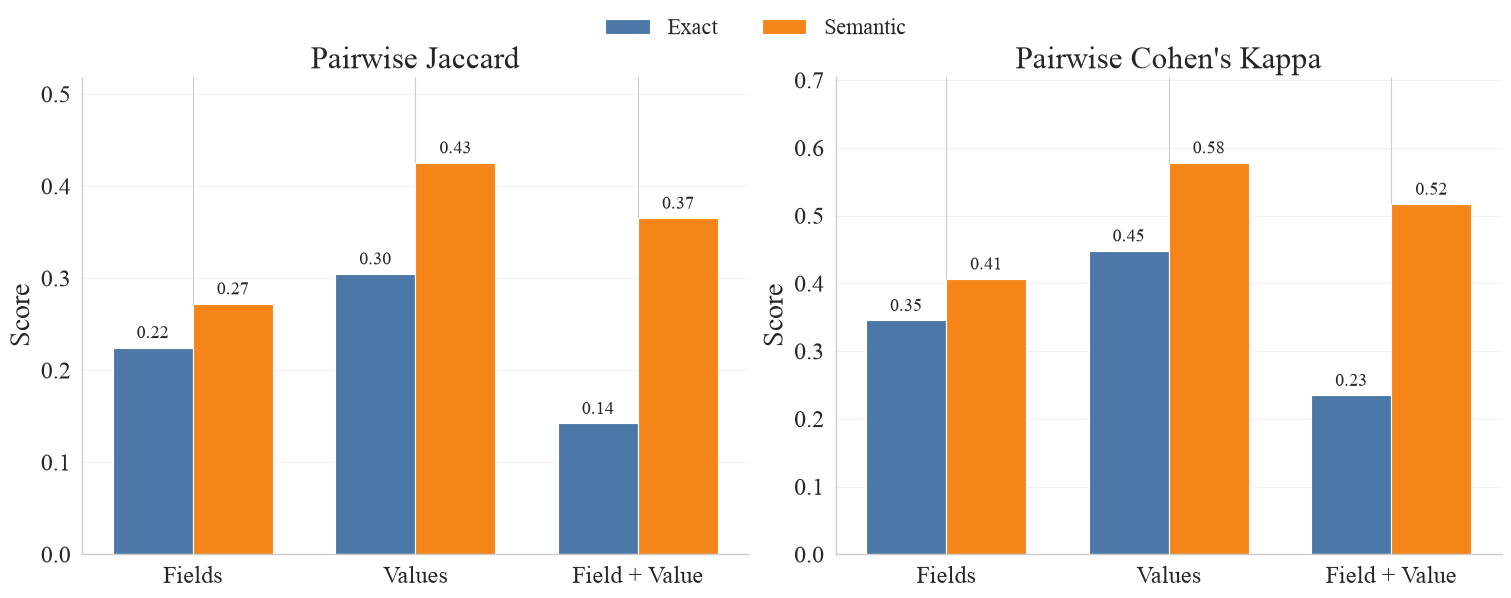

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

exact_j = [exact["overall"]["averages"][v]["average_jaccard"] for v in VIEWS]
sem_j = [semantic["overall"]["averages"][v]["average_jaccard"] for v in VIEWS]
grouped_exact_semantic_bars(axes[0], exact_j, sem_j, "Pairwise Jaccard")

exact_k = [exact["overall"]["averages"][v]["average_cohen_kappa"] for v in VIEWS]
sem_k = [semantic["overall"]["averages"][v]["average_cohen_kappa"] for v in VIEWS]
grouped_exact_semantic_bars(axes[1], exact_k, sem_k, "Pairwise Cohen's Kappa")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
save_figure(fig, "fig1_exact_vs_semantic_pairwise")
plt.show()

## Figure 2: Exact vs Semantic Multi-Model Agreement

Saved results/figures/fig2_exact_vs_semantic_multimodel.png
Saved results/figures/fig2_exact_vs_semantic_multimodel.pdf


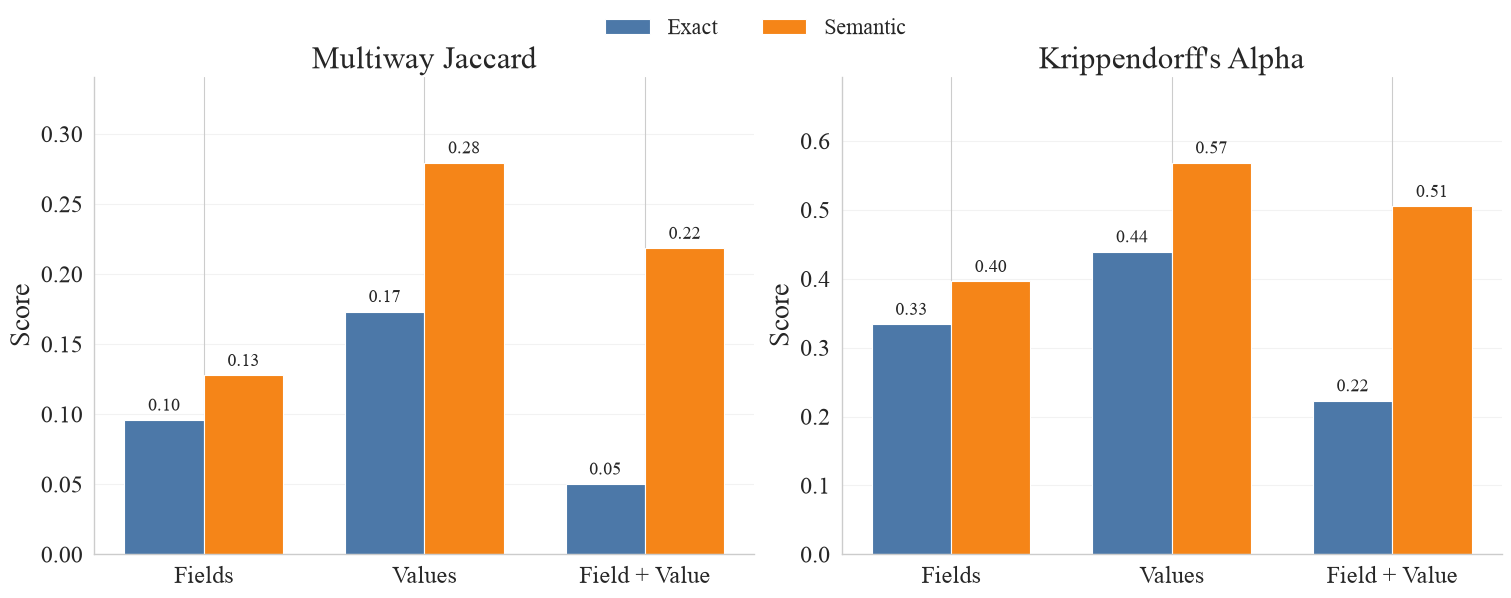

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)

exact_mj = [exact["overall_multimodel"]["averages"][v]["average_multiway_jaccard"] for v in VIEWS]
sem_mj = [semantic["overall_multimodel"]["averages"][v]["average_multiway_jaccard"] for v in VIEWS]
grouped_exact_semantic_bars(axes[0], exact_mj, sem_mj, "Multiway Jaccard")

exact_a = [exact["overall_multimodel"]["averages"][v]["average_krippendorff_alpha"] for v in VIEWS]
sem_a = [semantic["overall_multimodel"]["averages"][v]["average_krippendorff_alpha"] for v in VIEWS]
grouped_exact_semantic_bars(axes[1], exact_a, sem_a, "Krippendorff's Alpha")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
save_figure(fig, "fig2_exact_vs_semantic_multimodel")
plt.show()

## Figure 3: Semantic Gain

Saved results/figures/fig3_semantic_gain.png
Saved results/figures/fig3_semantic_gain.pdf


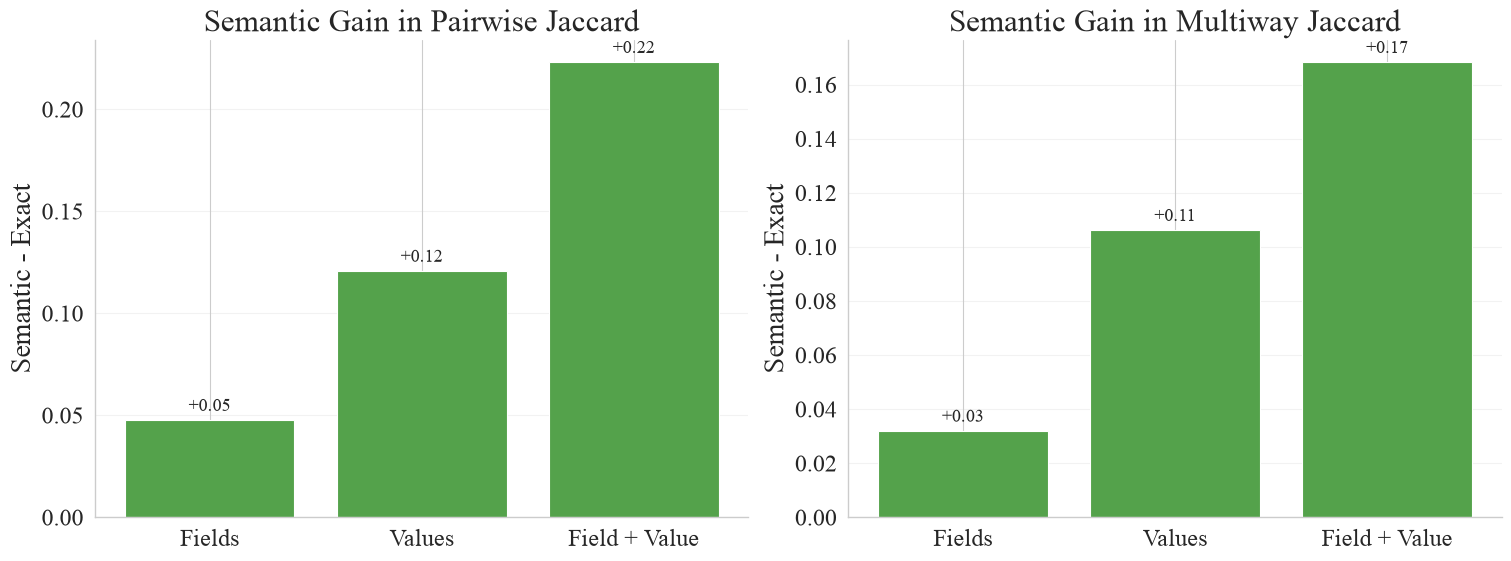

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), constrained_layout=True)
x = np.arange(len(VIEWS))

pairwise_gain = [
    semantic["overall"]["averages"][v]["average_jaccard"] - exact["overall"]["averages"][v]["average_jaccard"]
    for v in VIEWS
]
bars = axes[0].bar(x, pairwise_gain, color=COLORS["gain"])
axes[0].set_title("Semantic Gain in Pairwise Jaccard")
axes[0].set_ylabel("Semantic - Exact")
axes[0].set_xticks(x)
axes[0].set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
axes[0].grid(axis="y", alpha=0.25)
bar_label(axes[0], bars, fmt="+{:.2f}")

multi_gain = [
    semantic["overall_multimodel"]["averages"][v]["average_multiway_jaccard"] - exact["overall_multimodel"]["averages"][v]["average_multiway_jaccard"]
    for v in VIEWS
]
bars = axes[1].bar(x, multi_gain, color=COLORS["gain"])
axes[1].set_title("Semantic Gain in Multiway Jaccard")
axes[1].set_ylabel("Semantic - Exact")
axes[1].set_xticks(x)
axes[1].set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
axes[1].grid(axis="y", alpha=0.25)
bar_label(axes[1], bars, fmt="+{:.2f}")

save_figure(fig, "fig3_semantic_gain")
plt.show()

## Figure 4: Pairwise Jaccard Heatmaps

Saved results/figures/fig4_pairwise_jaccard_heatmaps.png
Saved results/figures/fig4_pairwise_jaccard_heatmaps.pdf


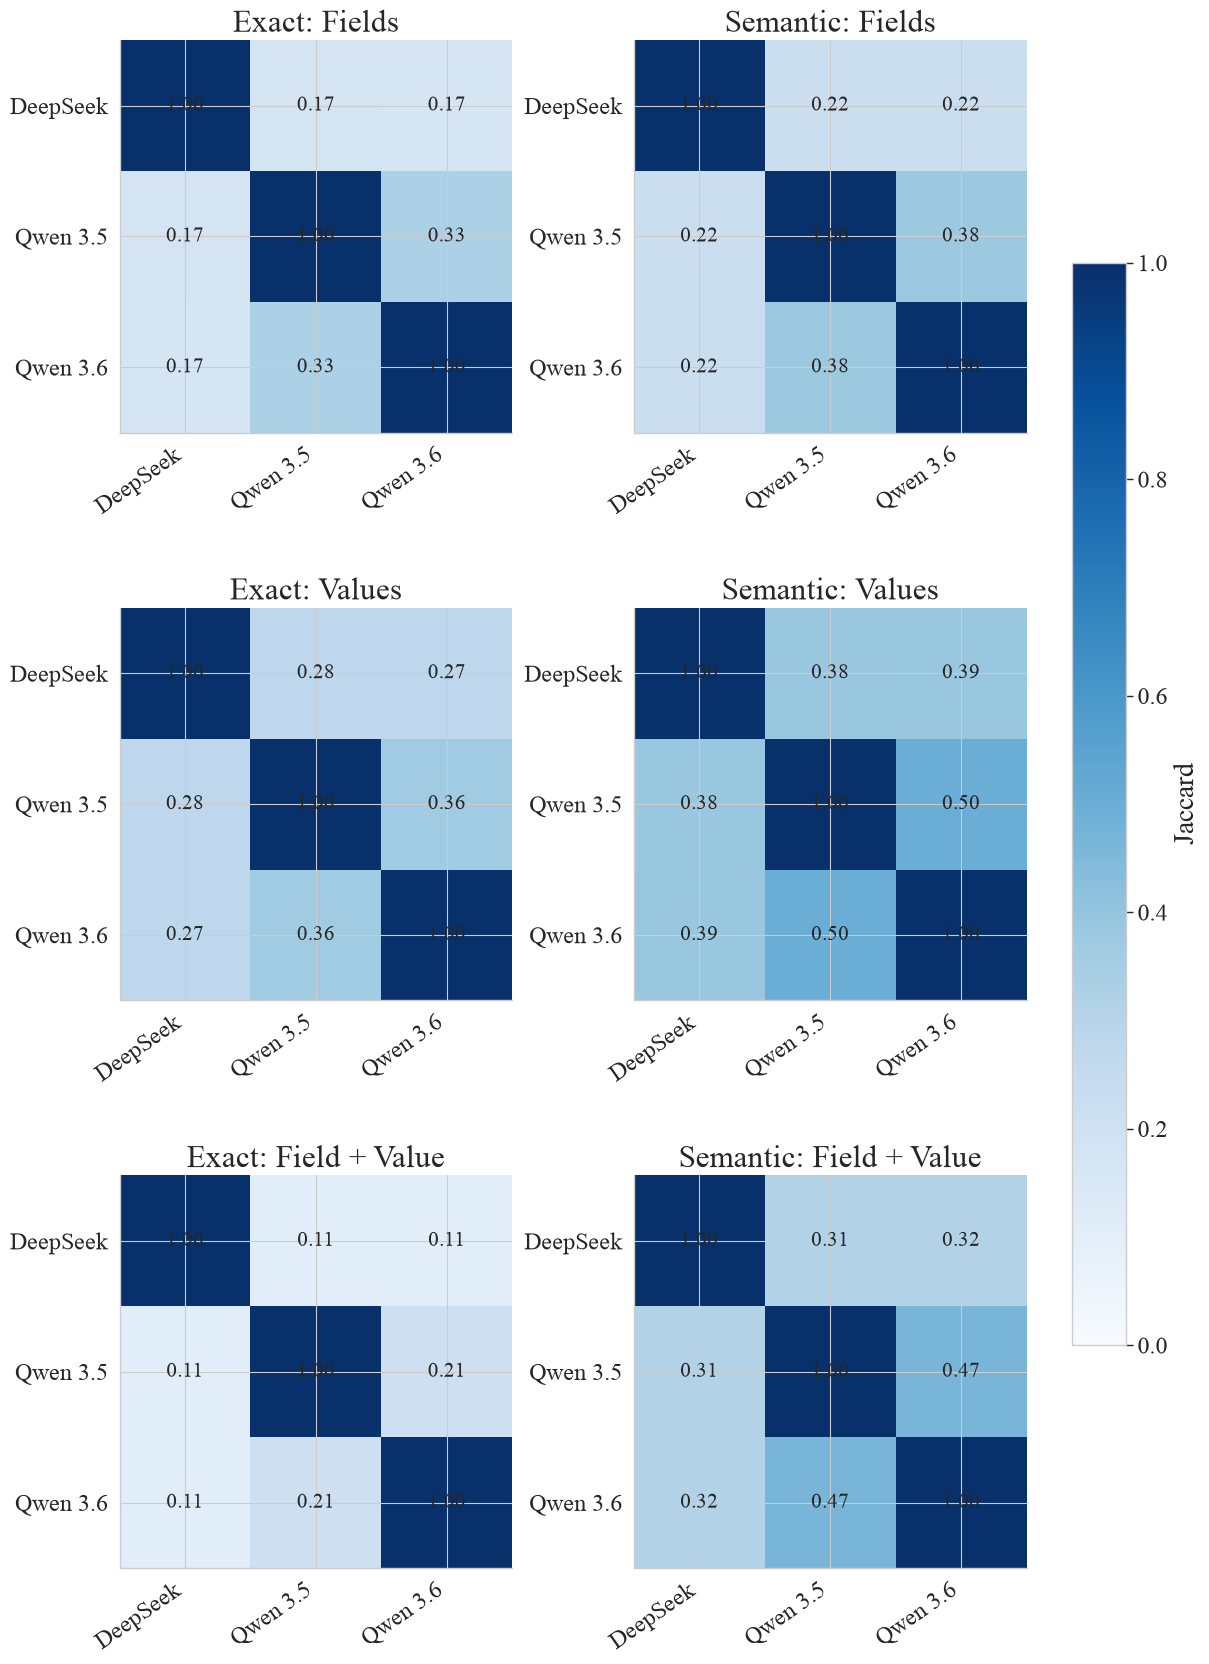

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 17), constrained_layout=True)

for row, view in enumerate(VIEWS):
    models, exact_matrix = pairwise_matrix(exact, view, "average_jaccard")
    _, semantic_matrix = pairwise_matrix(semantic, view, "average_jaccard")
    labels = [MODEL_LABELS.get(m, m) for m in models]
    im = draw_heatmap(axes[row, 0], exact_matrix, labels, f"Exact: {VIEW_LABELS[view]}")
    draw_heatmap(axes[row, 1], semantic_matrix, labels, f"Semantic: {VIEW_LABELS[view]}")

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.65, label="Jaccard")
save_figure(fig, "fig4_pairwise_jaccard_heatmaps")
plt.show()

## Figure 5: Semantic Clustering Compression

Saved results/figures/fig5_semantic_clustering_compression.png
Saved results/figures/fig5_semantic_clustering_compression.pdf


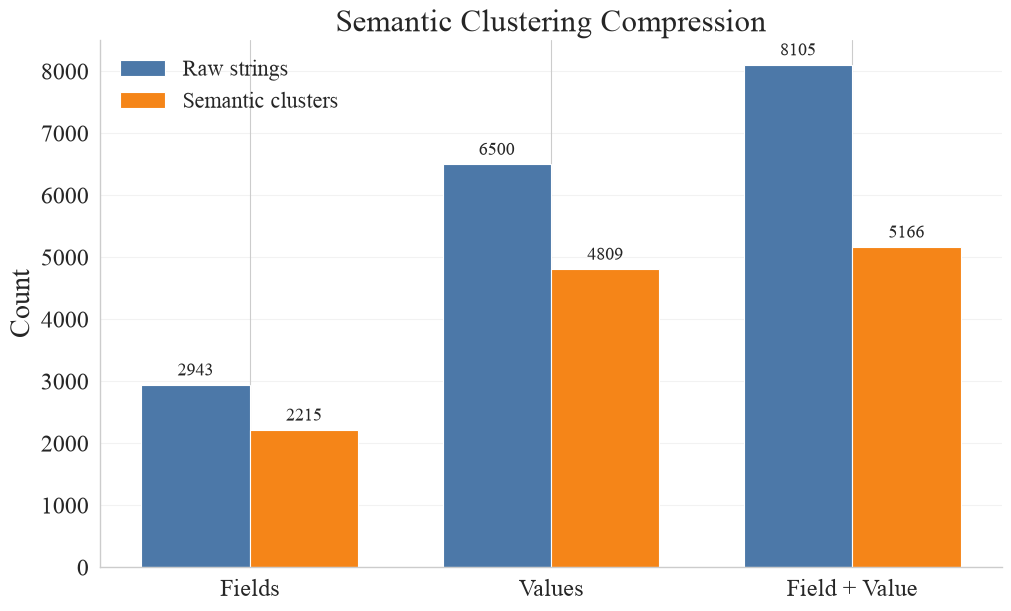

In [9]:
clusters = semantic["semantic"]["clusters"]
raw_counts = [clusters[v]["raw_item_count"] for v in VIEWS]
cluster_counts = [clusters[v]["cluster_count"] for v in VIEWS]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
x = np.arange(len(VIEWS))
width = 0.36
b1 = ax.bar(x - width / 2, raw_counts, width, label="Raw strings", color=COLORS["exact"])
b2 = ax.bar(x + width / 2, cluster_counts, width, label="Semantic clusters", color=COLORS["semantic"])
ax.set_title("Semantic Clustering Compression")
ax.set_ylabel("Count")
ax.set_xticks(x)
ax.set_xticklabels([VIEW_LABELS[v] for v in VIEWS])
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
bar_label(ax, b1, fmt="{:.0f}")
bar_label(ax, b2, fmt="{:.0f}")

save_figure(fig, "fig5_semantic_clustering_compression")
plt.show()